# California Cities: Water Area Analysis

## 1. Load and inspect the data

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [41]:
data = pd.read_csv("H:\\Training for Interview - PART INC\\Github\\MasterClass-FinTech-01\\session_1\\2.california_cities\\california_cities.csv")
print("Shape (rows, columns):", data.shape)
data.head()


Shape (rows, columns): (482, 14)


,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [42]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    object 
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), object(1)
memory usage: 52.8+ KB


'Unnamed: 0' is just the old index saved by to_csv, so I'll drop it

In [43]:
data = data.drop(columns="Unnamed: 0")
data.columns.tolist()

['city',
 'latd',
 'longd',
 'elevation_m',
 'elevation_ft',
 'population_total',
 'area_total_sq_mi',
 'area_land_sq_mi',
 'area_water_sq_mi',
 'area_total_km2',
 'area_land_km2',
 'area_water_km2',
 'area_water_percent']

## 2. Data types and missing values (water-area columns)

In [44]:
water_cols = ["area_water_sq_mi", "area_water_km2", "area_water_percent"]

print(data[water_cols].dtypes)
print()
print(data[water_cols].isna().sum())

area_water_sq_mi      float64
area_water_km2        float64
area_water_percent    float64
dtype: object

area_water_sq_mi      1
area_water_km2        4
area_water_percent    5
dtype: int64


which cities are affected?

In [45]:
missing_mask = data[water_cols].isna().any(axis=1)
data.loc[missing_mask, ["city"] + water_cols]

,city,area_water_sq_mi,area_water_km2,area_water_percent
143,FortBragg,NaN,0.1,NaN
197,JurupaValley,0.200,0.6,NaN
237,LosAltos,0.000,NaN,NaN
370,SanFrancisco,185.020,NaN,80.0
393,SantaMonica,0.001,NaN,NaN
443,UnionCity,0.000,NaN,NaN


sanity check: sq mi -> km2 should be about x 2.59, so missing km2 values
could be rebuilt from sq mi if I wanted to

In [46]:
ratio = (data["area_water_km2"] / data["area_water_sq_mi"]).replace([np.inf, -np.inf], np.nan)
print("median ratio:", np.round(ratio.median(), 3))

median ratio: 2.59


All three columns are `float64`, so no type conversion is needed. A few values are missing (4 in `area_water_km2`). 
I'm **not** filling them: a missing water area is not the same thing as zero, and only 4 of 482 rows are affected. 
They are dropped for the ranking, and `sort_values` would push them to the bottom anyway.

## 3. Rank cities by `area_water_km2` (top 5)

SQL equivalent:
SELECT city, area_water_km2 FROM cities
WHERE area_water_km2 IS NOT NULL
ORDER BY area_water_km2 DESC LIMIT 5;

In [51]:
ranked = data.dropna(subset=["area_water_km2"]).sort_values("area_water_km2", ascending=False)
top5 = ranked[["city", "area_water_km2"]].head(5).reset_index(drop=True)
top5.index = top5.index + 1   # rank from 1
top5

,city,area_water_km2
1,SanDiego,122.270
2,LosAngeles,88.000
3,NewportBeach,75.557
4,Coronado,64.062
5,DanaPoint,59.536


## 4. Bar chart

barh draws the first item at the bottom, so sort ascending
(or I could call ax.invert_yaxis())

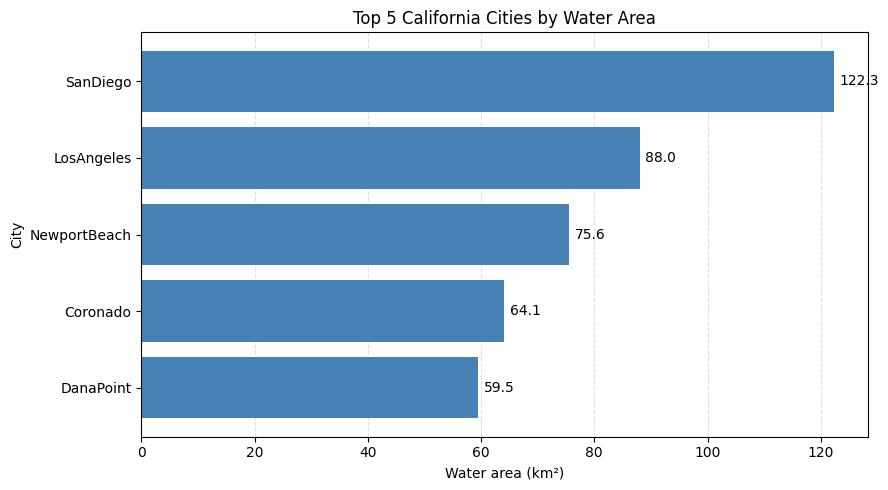

In [ ]:
plot_data = top5.sort_values("area_water_km2", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data["city"], plot_data["area_water_km2"], color="steelblue")


for i, v in enumerate(plot_data["area_water_km2"]):
    ax.text(v + 1, i, f"{v:.1f}", va="center")

ax.set_xlabel("Water area (km²)")
ax.set_ylabel("City")
ax.set_title("Top 5 California Cities by Water Area")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Takeaway:** San Diego has by far the largest water area (about 122 km²), roughly 1.4x Los Angeles in second place. 
The top five are all coastal cities, which makes sense since their boundaries include bays and ocean water.